In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/haberman/haberman.data"

df = pd.read_csv(url, header=None)

df.columns = [
    "age",
    "operation_year",
    "positive_nodes",
    "survival_status"
]

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [3]:
print("First 5 rows:")
print(df.head())

print("\nLast 5 rows:")
print(df.tail())

print("\nDataset shape:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe())

First 5 rows:
   age  operation_year  positive_nodes  survival_status
0   30              64               1                1
1   30              62               3                1
2   30              65               0                1
3   31              59               2                1
4   31              65               4                1

Last 5 rows:
     age  operation_year  positive_nodes  survival_status
301   75              62               1                1
302   76              67               0                1
303   77              65               3                1
304   78              65               1                2
305   83              58               2                2

Dataset shape:
(306, 4)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 306 entries, 0 to 305
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              306 non-null    int64
 1   

In [4]:
print("Missing values:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
age                0
operation_year     0
positive_nodes     0
survival_status    0
dtype: int64

Total missing values:
0

Duplicate rows:
17


In [5]:
status_counts = df["survival_status"].value_counts().sort_index()

print("Survival Status Counts:")
print(status_counts)

Survival Status Counts:
survival_status
1    225
2     81
Name: count, dtype: int64


In [6]:
ages = df["age"].to_numpy()

print("Average Age:", np.mean(ages))
print("Median Age:", np.median(ages))
print("Minimum Age:", np.min(ages))
print("Maximum Age:", np.max(ages))

Average Age: 52.45751633986928
Median Age: 52.0
Minimum Age: 30
Maximum Age: 83


In [7]:
nodes = df["positive_nodes"].to_numpy()

average_nodes = np.mean(nodes)

print("Average Positive Axillary Nodes:", average_nodes)

Average Positive Axillary Nodes: 4.026143790849673


In [8]:
group_comparison = df.groupby("survival_status")[
    ["age", "positive_nodes"]
].mean()

print("Average Age and Nodes by Survival Status:")
print(group_comparison)

Average Age and Nodes by Survival Status:
                       age  positive_nodes
survival_status                           
1                52.017778        2.791111
2                53.679012        7.456790


In [9]:
year_counts = df["operation_year"].value_counts().sort_index()

print("Records per Operation Year:")
print(year_counts)

print("\nYears ranked by number of records:")
print(df["operation_year"].value_counts().sort_values(ascending=False))

Records per Operation Year:
operation_year
58    36
59    27
60    28
61    26
62    23
63    30
64    31
65    28
66    28
67    25
68    13
69    11
Name: count, dtype: int64

Years ranked by number of records:
operation_year
58    36
64    31
63    30
65    28
66    28
60    28
59    27
61    26
67    25
62    23
68    13
69    11
Name: count, dtype: int64


In [10]:
year_counts_full = year_counts.copy()
year_counts_full.index = year_counts_full.index + 1900

print("\nOperation Year Counts:")
print(year_counts_full)


Operation Year Counts:
operation_year
1958    36
1959    27
1960    28
1961    26
1962    23
1963    30
1964    31
1965    28
1966    28
1967    25
1968    13
1969    11
Name: count, dtype: int64


In [11]:
# Filter patients aged 50 or above
older_patients = df[df["age"] >= 50]

print("Patients aged 50 or above:")
print(older_patients.head())

# Sort by age in descending order
sorted_data = df.sort_values(by="age", ascending=False)

print("\nData sorted by age:")
print(sorted_data.head(10))

Patients aged 50 or above:
     age  operation_year  positive_nodes  survival_status
124   50              63              13                2
125   50              64               0                2
126   50              59               0                1
127   50              61               6                1
128   50              61               0                1

Data sorted by age:
     age  operation_year  positive_nodes  survival_status
305   83              58               2                2
304   78              65               1                2
303   77              65               3                1
302   76              67               0                1
301   75              62               1                1
299   74              65               3                2
300   74              63               0                1
297   73              62               0                1
298   73              68               0                1
295   72              64

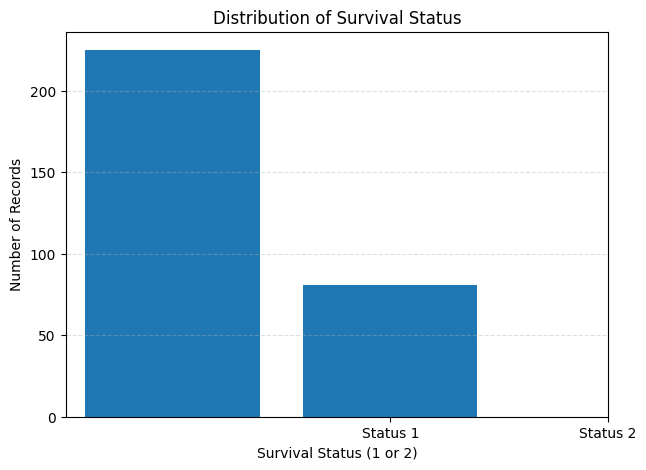

In [12]:
status_counts = df["survival_status"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(status_counts.index.astype(str), status_counts.values)

plt.title("Distribution of Survival Status")
plt.xlabel("Survival Status (1 or 2)")
plt.ylabel("Number of Records")

plt.xticks([1, 2], ["Status 1", "Status 2"])
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

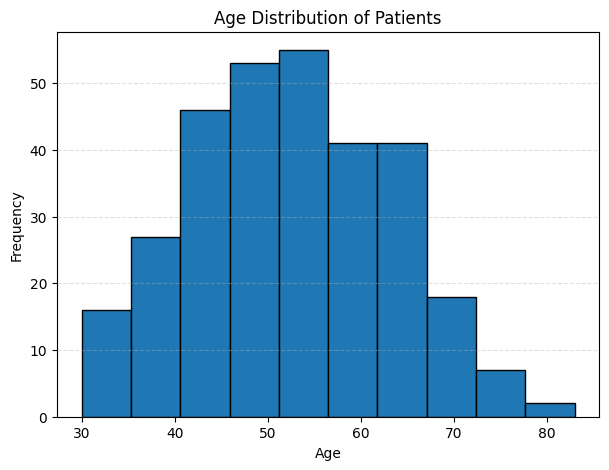

In [13]:
plt.figure(figsize=(7, 5))

plt.hist(df["age"], bins=10, edgecolor="black")

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

In [14]:
print("========== PROJECT SUMMARY ==========")

print("Total Records:", df.shape[0])

print("\nSurvival Status Counts:")
print(df["survival_status"].value_counts().sort_index())

print("\nAge Statistics:")
print("Average:", round(np.mean(ages), 2))
print("Median:", np.median(ages))
print("Minimum:", np.min(ages))
print("Maximum:", np.max(ages))

print("\nAverage Positive Nodes:")
print(round(np.mean(nodes), 2))

print("\nAverage Values by Survival Status:")
print(group_comparison)

print("\nOperation Year with Most Records:")
print(year_counts_full.sort_values(ascending=False).head())

print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

========== PROJECT SUMMARY ==========
Total Records: 306

Survival Status Counts:
survival_status
1    225
2     81
Name: count, dtype: int64

Age Statistics:
Average: 52.46
Median: 52.0
Minimum: 30
Maximum: 83

Average Positive Nodes:
4.03

Average Values by Survival Status:
                       age  positive_nodes
survival_status                           
1                52.017778        2.791111
2                53.679012        7.456790

Operation Year with Most Records:
operation_year
1958    36
1964    31
1963    30
1960    28
1965    28
Name: count, dtype: int64

Missing Values: 0
Duplicate Rows: 17
